ANALYTICAL CLASS-E DESIGN
------------------------------------------------------------
KR = 0.576801, KC = 0.183601, KL = 1.152494
Ropt = 8.223 Ω, L1 = 107.73 nH, L2 = 280.44 nH, C2 = 460.83 pF
Csh ideal = 253.83 pF, P_gate = 8.05 mW
NOMINAL OPERATING-POINT COMPARISON (25°C vs 75°C)


,Tag,Model,Ron (Ω),C_ext (pF),IDC (mA),Vpk (V),V_turnon (V),iL_pk (A),i_sw_pk (A),P_load (mW),P_Ron (mW),P_ZVS (mW),η_sys (%),bal (mW),V_util (%),I_util (%)
0,A,"A: Constant-C, 25C",0.40,241.83,355.931,18.450,0.901,0.704,0.906,1615.931,109.082,1.442,93.174,-0.189,18.450,53.313
1,B,"B: Constant-C, 75C",0.52,241.83,349.923,18.199,0.996,0.692,0.890,1558.707,136.949,1.761,91.410,-0.288,18.199,52.379
2,C,"C: Power-law, 25C",0.40,247.33,348.016,18.135,0.934,0.694,2.335,1581.345,106.527,0.000,93.244,0.039,18.135,137.326
3,D,"D: Power-law, 75C",0.52,247.33,342.335,17.893,1.027,0.681,1.974,1526.637,133.683,0.000,91.505,0.040,17.893,116.128
4,E,"E: Table/Calib, 25C",0.40,247.33,347.378,18.071,0.933,0.692,2.332,1578.604,106.174,0.000,93.252,0.038,18.071,137.197
5,F,"F: Table/Calib, 75C",0.52,247.33,341.661,17.830,1.026,0.680,1.973,1523.819,133.232,0.000,91.515,0.039,17.830,116.036


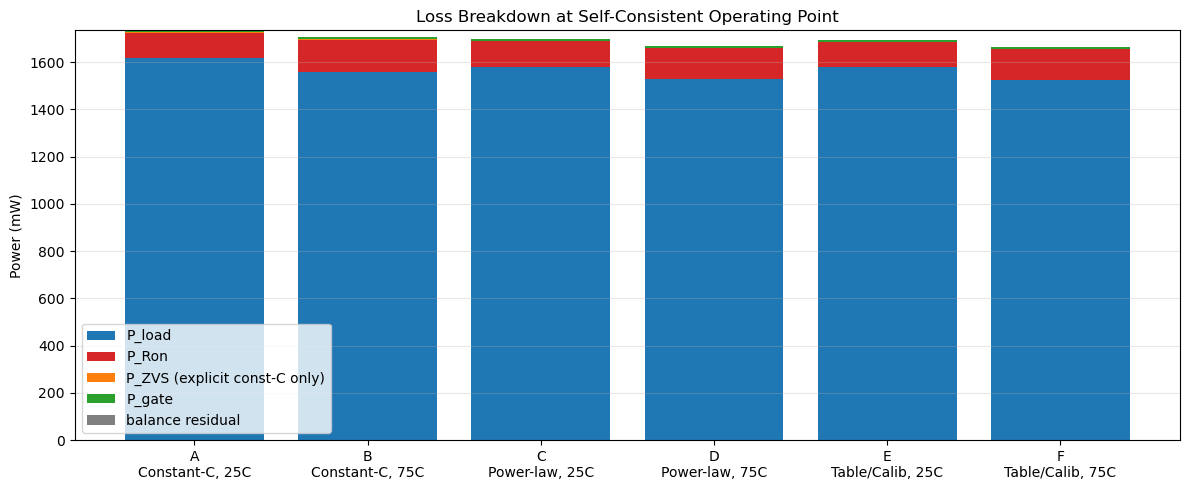

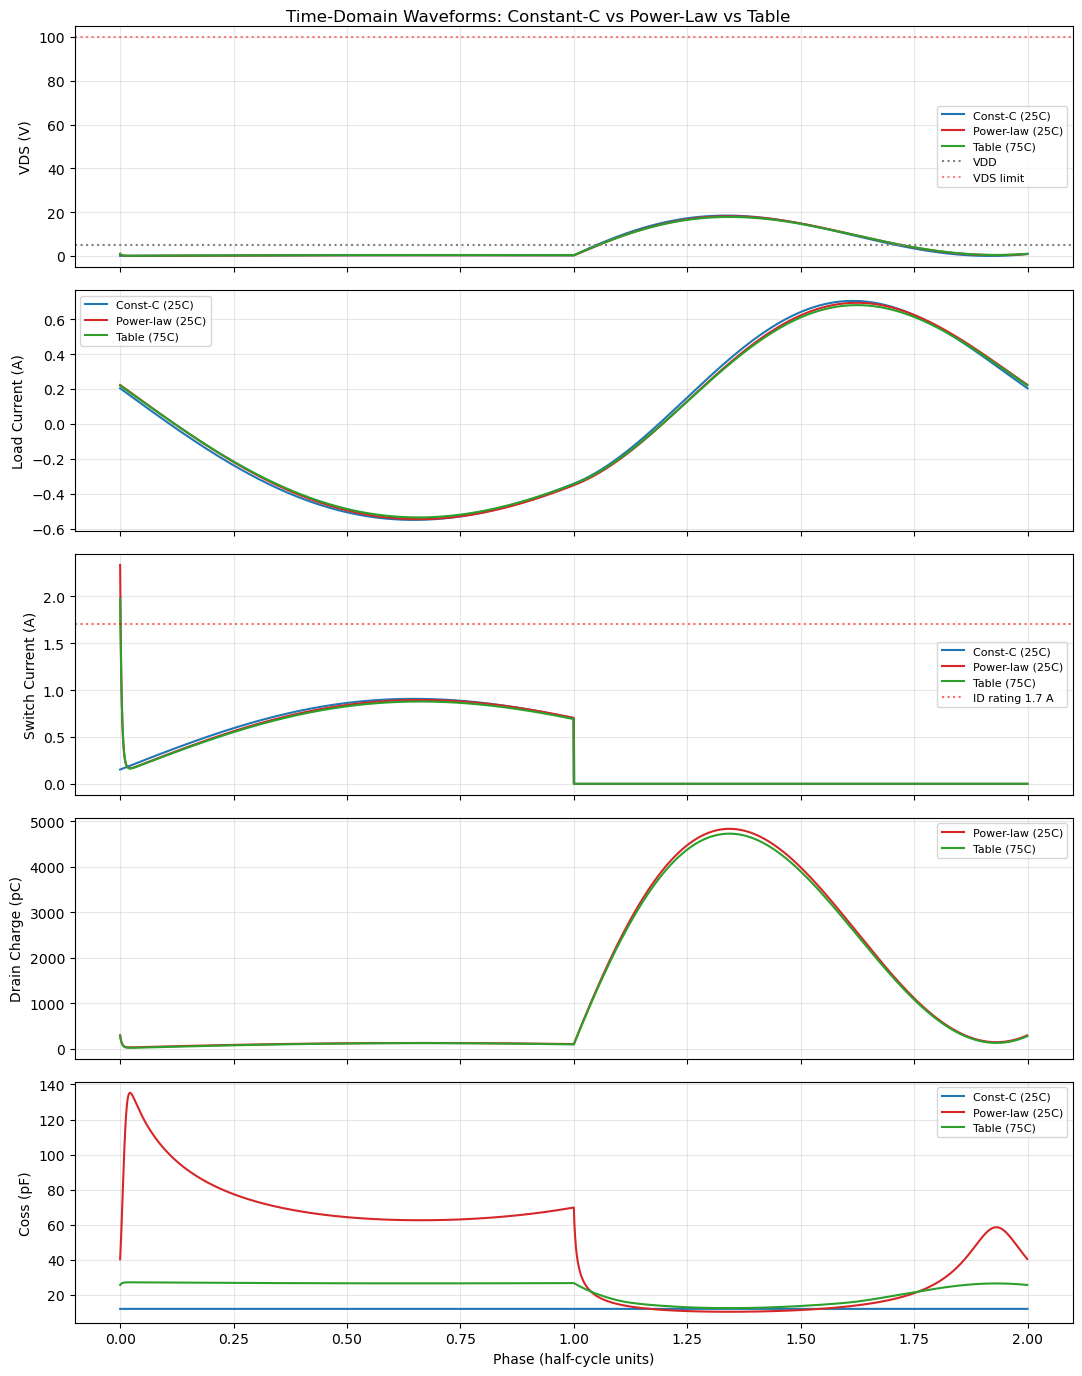

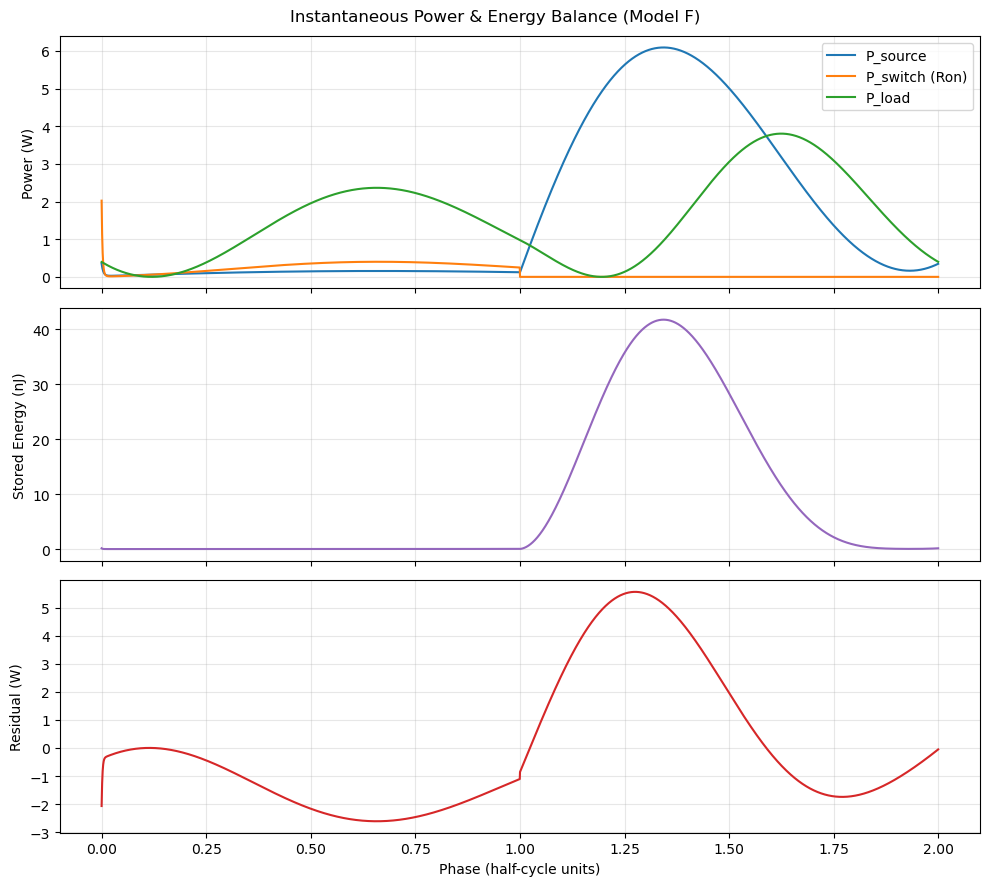

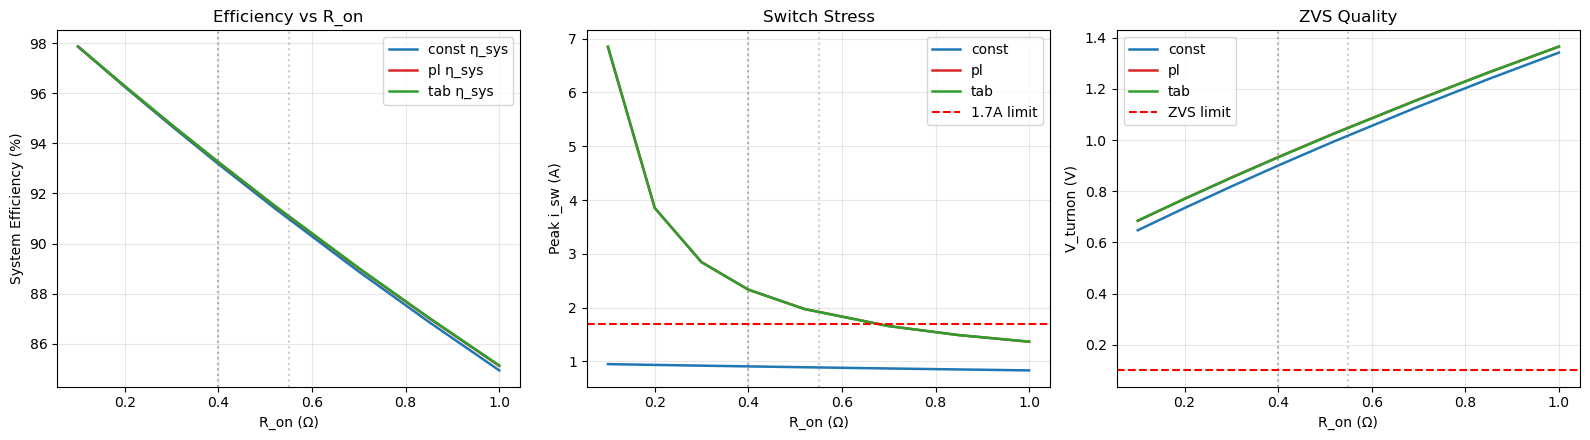

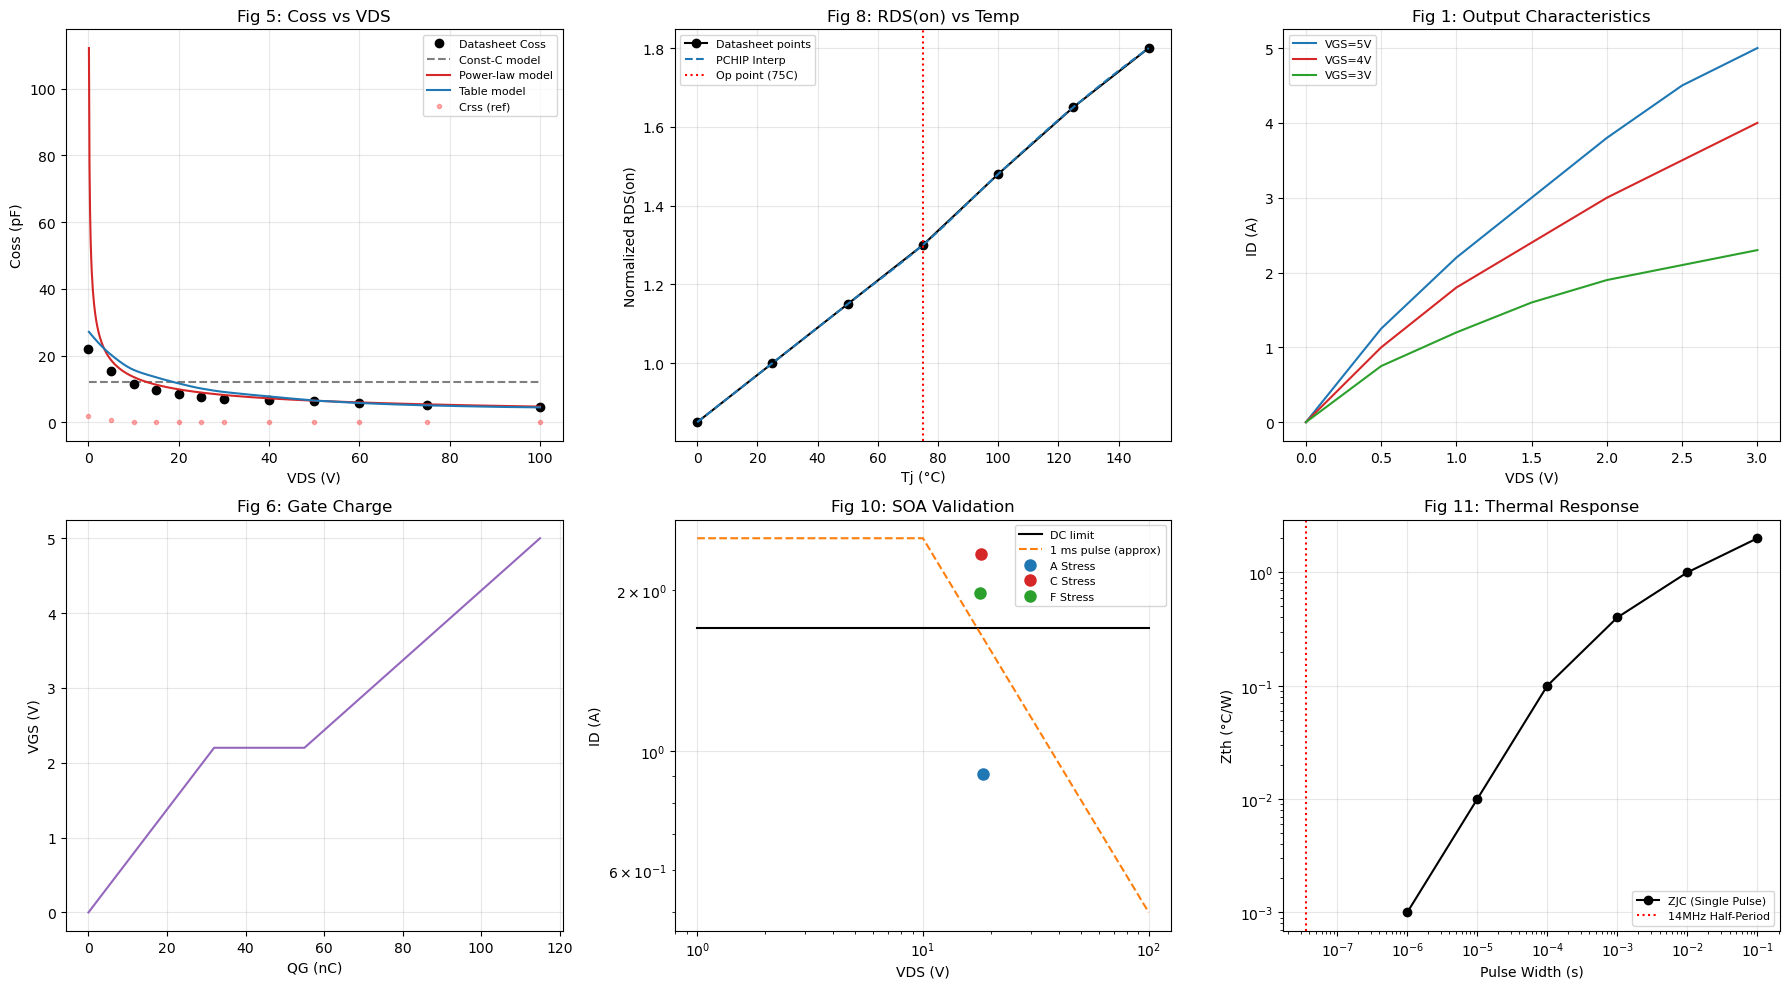

EXHAUSTIVE ENGINEERING FINDINGS
1) ZVS Quality & Switching Stress:
   - None of the models achieve textbook zero-voltage switching (ZVS).
   - Constant-C model predicts a small residual turn-on loss (P_ZVS ≈ 1-2 mW).
   - Nonlinear models predict a sharp turn-on current spike (>2.3 A) due to
     the highly nonlinear Coss curve. This exceeds the 1.7 A continuous rating.
   - Operating point F (Table model, 75C) hits i_sw,pk = 1.973 A, which is
     116.0% of the continuous limit.
   - SAFE OPERATING AREA: The voltage utilisation is very low (Vpk ≈ 18V vs 100V limit).
     The device is heavily current-limited. Pulsed SOA (Fig 10) indicates that
     short spikes at this power might be survivable, but careful thermal
     management is required.

2) Thermal Estimation (Model F):
   - Conduction loss (P_Ron) = 133.23 mW
   - At 14MHz (35ns half-period), transient Zth ≈ 0.0010 °C/W.
   - Estimated Tj rise = 0.00 °C above case.
   - Note: The R_on used in Model F already assumes Tj = 75°C 

In [1]:
# =============================================================================
# CONSOLIDATED EPC2037 GaN CLASS-E AMPLIFIER NOTEBOOK
# Merges: GaN.txt, GaNExtended.txt, GaNNonLinear.txt, GaNFullyNonLinear.txt
# Includes full datasheet validation (Figures 1-11) and comprehensive diagnostics
# =============================================================================

# =============================================================================
# Layer 1: Imports, Specifications, Analytical Class-E Network
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.optimize import brentq
from scipy.interpolate import PchipInterpolator
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)

# --- Global Specifications ---
VDD = 4.85
POUT = 1.65
F0 = 14.0e6
W0 = 2*np.pi*F0
T = 1/F0
TH = T/2

# --- Datasheet Parameters ---
VDS_MAX = 100.0
ID_MAX = 1.7
RON_25 = 0.400
RON_MAX_25 = 0.550
VG = 5.0
QG = 115e-12
QGS = 32e-12
QGD = 25e-12
RG = 0.5
PGATE = QG*VG*F0

CISS = 14e-12
CRSS = 0.1e-12
COSS_50 = 6.5e-12
COSS_ER = 9.5e-12
COSS_TR = 12e-12
QOSS_50 = 600e-12
COSS_50_MAX = 10e-12
QOSS_50_MAX = 900e-12
EOSS_ER_50 = 0.5*COSS_ER*50**2

# --- Analytical Class-E Design ---
a = 2/np.sqrt(np.pi**2 + 4)
phi = np.pi - np.arctan(2/np.pi)
KR = 2*a**2
KC = 2*a**2/np.pi

Ropt = KR*VDD**2/POUT
Csh_ideal = KC/(W0*Ropt)

# KL from fundamental Fourier component
IR_norm = np.sqrt(2/KR)
IDC_norm = a*IR_norm
C_norm = KC/KR
th = np.linspace(0, 2*np.pi, 200001)
vd_norm = np.zeros_like(th)
off = th >= np.pi
vd_norm[off] = (IDC_norm*(th[off]-np.pi) + IR_norm*(np.cos(th[off]+phi)-np.cos(np.pi+phi)))/C_norm
V1 = np.trapezoid(vd_norm*np.exp(-1j*th), th)/np.pi
I1 = IR_norm*np.exp(1j*(phi-np.pi/2))
Z1 = V1/I1
KL = Z1.imag/Z1.real

L1 = KL*Ropt/W0
QL = 3.0
L2 = QL*Ropt/W0
C2 = 1/(W0**2*L2)
LT = L1+L2
IDC_sk = POUT/VDD
IR_sk = np.sqrt(2*POUT/Ropt)

print("ANALYTICAL CLASS-E DESIGN")
print("-"*60)
print(f"KR = {KR:.6f}, KC = {KC:.6f}, KL = {KL:.6f}")
print(f"Ropt = {Ropt:.3f} Ω, L1 = {L1*1e9:.2f} nH, L2 = {L2*1e9:.2f} nH, C2 = {C2*1e12:.2f} pF")
print(f"Csh ideal = {Csh_ideal*1e12:.2f} pF, P_gate = {PGATE*1e3:.2f} mW")


# =============================================================================
# Layer 2: Datasheet Digitization & Validation Models (Kennlinien)
# =============================================================================
# Digitized data points extracted from the provided EPC2037 datasheet images
# (Figures 1, 3, 4, 5, 6, 8, 10, 11)

# Fig 5a: Capacitance vs VDS
DS_FIG5_VDS = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 75, 100.])
DS_FIG5_COSS = 1e-12*np.array([22.0, 15.5, 11.5, 9.8, 8.5, 7.5, 7.0, 6.7, 6.5, 5.8, 5.1, 4.5])
DS_FIG5_CRSS = 1e-12*np.array([2.0, 0.7, 0.2, 0.15, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.08, 0.05])
DS_FIG5_CISS = np.full_like(DS_FIG5_VDS, 14.0e-12)

# Fig 8: Normalized RDS(on) vs Tj
DS_FIG8_TJ = np.array([0, 25, 50, 75, 100, 125, 150.])
DS_FIG8_RDS_NORM = np.array([0.85, 1.00, 1.15, 1.30, 1.48, 1.65, 1.80])
_rds_curve = PchipInterpolator(DS_FIG8_TJ, DS_FIG8_RDS_NORM, extrapolate=False)
def temperature_factor(Tj):
    if Tj < 0 or Tj > 150: raise ValueError("Temperature outside digitized range.")
    return float(_rds_curve(Tj))

# Fig 10: Safe Operating Area (SOA)
DS_FIG10_VDS = np.array([1, 10, 100])
DS_FIG10_ID_DC = np.array([1.7, 1.7, 1.7])
DS_FIG10_ID_1MS = np.array([2.5, 2.5, 0.5])  # Approximate from image

# Fig 11: Thermal Impedance (Single Pulse)
DS_FIG11_T = np.array([1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1])
DS_FIG11_ZJC = np.array([0.001, 0.01, 0.1, 0.4, 1.0, 2.0]) # Approximate normalized

# Fig 1, 3, 4: Output & Transfer Characteristics (Approximate)
DS_FIG1_VDS = np.array([0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0])
DS_FIG1_ID_5V = np.array([0, 1.25, 2.2, 3.0, 3.8, 4.5, 5.0])
DS_FIG1_ID_4V = np.array([0, 1.0, 1.8, 2.4, 3.0, 3.5, 4.0])
DS_FIG1_ID_3V = np.array([0, 0.75, 1.2, 1.6, 1.9, 2.1, 2.3])

# Fig 6: Gate Charge
DS_FIG6_QG = np.array([0, 0.032, 0.055, 0.115])
DS_FIG6_VGS = np.array([0, 2.2, 2.2, 5.0])

# Now initialize models (Constant, Power-law, Table)
COSS_CONST = COSS_TR
M_PL = COSS_50*50/QOSS_50

V_COSS_RAW = DS_FIG5_VDS
C_COSS_RAW = DS_FIG5_COSS
_coss_dig = PchipInterpolator(V_COSS_RAW, C_COSS_RAW, extrapolate=False)
V_GRID = np.linspace(0, 100, 100001)
C_GRID_RAW = _coss_dig(V_GRID)
Q_GRID_RAW = cumulative_trapezoid(C_GRID_RAW, V_GRID, initial=0)
Q_RAW_50 = Q_GRID_RAW[np.argmin(np.abs(V_GRID-50))]
CAL_A = (QOSS_50-Q_RAW_50)/25.0
C_GRID = C_GRID_RAW.copy()
C_GRID[V_GRID <= 50] += CAL_A*(1-V_GRID[V_GRID <= 50]/50)
Q_GRID = cumulative_trapezoid(C_GRID, V_GRID, initial=0)
E_GRID = cumulative_trapezoid(V_GRID*C_GRID, V_GRID, initial=0)

_qoss_tab = PchipInterpolator(V_GRID, Q_GRID)
_eoss_tab = PchipInterpolator(V_GRID, E_GRID)
_coss_tab = PchipInterpolator(V_GRID, C_GRID)

def qoss_const(v): return COSS_CONST*np.abs(np.asarray(v, float))
def coss_const(v): return np.full_like(np.asarray(v, float), COSS_CONST)
def eoss_const(v): return 0.5*COSS_CONST*np.asarray(v, float)**2

def qoss_pl(v): return QOSS_50*(np.abs(np.asarray(v, float))/50)**M_PL
def coss_pl(v): return M_PL*QOSS_50/50*(np.maximum(np.abs(np.asarray(v, float)), 1e-12)/50)**(M_PL-1)
def eoss_pl(v): return M_PL/(M_PL+1)*QOSS_50*50*(np.abs(np.asarray(v, float))/50)**(M_PL+1)

def qoss_tab(v): return np.sign(v)*_qoss_tab(np.abs(v))
def coss_tab(v): return _coss_tab(np.clip(np.abs(v), 0, 100))
def eoss_tab(v): return _eoss_tab(np.abs(v))


# =============================================================================
# Layer 3: Device Models & Power Accounting
# =============================================================================
class DeviceModel:
    def __init__(self, name, coss_f, qoss_f, eoss_f, Cext, Ron, kind="nonlin"):
        self.name = name; self.coss_f = coss_f; self.qoss_f = qoss_f; self.eoss_f = eoss_f
        self.Cext = float(Cext); self.Ron = float(Ron); self.kind = kind
        self._vg = np.linspace(0, 60, 60001)
        self._qg = self.Cext*self._vg + np.asarray(self.qoss_f(self._vg), float)
    def v_from_q(self, q):
        q = float(q)
        if abs(q) < 1e-30: return 0.0
        return np.sign(q)*float(np.interp(abs(q), self._qg, self._vg))
    def e_total(self, v): return 0.5*self.Cext*np.asarray(v, float)**2 + np.asarray(self.eoss_f(v), float)

def report(h, IDC, model):
    t, iL, iSW, vD = h["t"], h["i_L"], h["i_sw"], h["v_D"]
    P_in = VDD*IDC
    P_load = np.trapezoid(Ropt*iL**2, t)/T
    P_Ron = model.Ron*np.trapezoid(iSW**2, t)/T
    P_src = np.trapezoid(vD*IDC, t)/T if model.kind != "const" else P_in
    P_ZVS = 0.5*Csh_ideal*h["v_turnon"]**2*F0 if model.kind == "const" else 0.0
    balance = P_src - P_load - P_Ron - P_ZVS
    E_turn = float(model.e_total(h["v_turnon"])) if model.kind != "const" else 0.5*Csh_ideal*h["v_turnon"]**2
    return {
        "P_in": P_in, "P_source": P_src, "P_load": P_load, "P_Ron": P_Ron, "P_ZVS": P_ZVS,
        "P_gate": PGATE, "P_total": P_in+PGATE, "balance": balance,
        "eta_drain": P_load/P_in, "eta_system": P_load/(P_in+PGATE),
        "E_turnon": E_turn, "Pout_error": P_load-POUT,
    }


# =============================================================================
# Layer 4: Simulation Engines (GaNExtended / GaNNonLinear)
# =============================================================================

# --- Constant-C Engine (GaN.txt / GaNExtended.txt) ---
def cycle_const(IDC, Ron, warmup=500, samples=1000):
    def f_on(t, y):
        iL, vC2 = y
        return [(Ron*(IDC-iL) - vC2 - Ropt*iL)/LT, iL/C2]
    def f_off(t, y):
        vD, iL, vC2 = y
        return [(IDC-iL)/Csh_ideal, (vD-vC2-Ropt*iL)/LT, iL/C2]
    iL, vC2 = 0.0, 0.0
    for _ in range(warmup):
        s1 = solve_ivp(f_on, [0, TH], [iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13)
        iL, vC2 = s1.y[0, -1], s1.y[1, -1]
        s2 = solve_ivp(f_off, [0, TH], [Ron*(IDC-iL), iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True)
        iL, vC2 = s2.y[1, -1], s2.y[2, -1]
    s1 = solve_ivp(f_on, [0, TH], [iL, vC2], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True)
    iL_on, vC2_on = s1.y[0, -1], s1.y[1, -1]
    s2 = solve_ivp(f_off, [0, TH], [Ron*(IDC-iL_on), iL_on, vC2_on], method="LSODA", rtol=1e-10, atol=1e-13, dense_output=True)
    
    t_on, t_off = np.linspace(0, TH, samples+1), np.linspace(0, TH, samples+1)
    y_on, y_off = s1.sol(t_on), s2.sol(t_off)
    t = np.concatenate([t_on, TH+t_off[1:]])
    vD = np.concatenate([Ron*(IDC-y_on[0]) if Ron > 0 else np.zeros_like(t_on), y_off[0][1:]])
    iL_f = np.concatenate([y_on[0], y_off[1][1:]])
    i_sw = np.concatenate([IDC-y_on[0], np.zeros_like(y_off[1][1:])])
    return {"t": t, "v_D": vD, "i_L": iL_f, "i_sw": i_sw, "v_avg": np.trapezoid(vD, t)/T,
            "v_peak": vD.max(), "v_turnon": float(s2.sol(TH)[0]), "i_turnon": float(s2.sol(TH)[1]), "periodic_error": 0.0}

# --- Nonlinear Charge Engine (GaNNonLinear.txt / GaNFullyNonLinear.txt) ---
def cycle_nonlin(IDC, dev, warmup=300, samples=1200):
    def f_on(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL-vD/dev.Ron, (vD-v2-Ropt*iL)/LT, iL/C2]
    def f_off(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL, (vD-v2-Ropt*iL)/LT, iL/C2]
    y = np.zeros(3); err = 0.0
    for _ in range(warmup):
        s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12)
        s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12)
        yn = s2.y[:, -1]; err = np.max(np.abs(yn-y)); y = yn
        if err < 1e-10: break
    s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True)
    s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True)
    
    t1, t2 = np.linspace(0, TH, samples, endpoint=False), np.linspace(0, TH, samples, endpoint=False)
    y1, y2 = s1.sol(t1), s2.sol(t2)
    q = np.r_[y1[0], y2[0]]; iL = np.r_[y1[1], y2[1]]; v2 = np.r_[y1[2], y2[2]]
    t = np.r_[t1, TH+t2]; vD = np.array([dev.v_from_q(z) for z in q]); iSW = np.r_[vD[:samples]/dev.Ron, np.zeros(samples)]
    return {"t": t, "q": q, "v_D": vD, "i_L": iL, "i_sw": iSW, "v2": v2, "v_avg": np.trapezoid(vD, t)/T,
            "v_peak": np.max(vD), "v_min": np.min(vD), "v_turnon": float(dev.v_from_q(s2.y[0, -1])),
            "i_turnon": float(s2.y[1, -1]), "periodic_error": err}

def solve_const(Ron):
    def resid(I): return cycle_const(I, Ron, warmup=200)["v_avg"] - VDD
    I = brentq(resid, 0.7*IDC_sk, 1.3*IDC_sk, xtol=1e-7)
    h = cycle_const(I, Ron, warmup=500)
    return h, I, h["v_avg"]-VDD

def solve_nonlin(dev):
    def resid(I): return cycle_nonlin(I, dev, warmup=200)["v_avg"] - VDD
    lo, hi = 0.05*POUT/VDD, 3.0*POUT/VDD
    I = brentq(resid, lo, hi, xtol=1e-8)
    h = cycle_nonlin(I, dev, warmup=500, samples=1600)
    return h, I, h["v_avg"]-VDD

def run_point(kind, Ron, label):
    if kind == "const":
        dev = DeviceModel(label, coss_const, qoss_const, eoss_const, Csh_ideal-COSS_TR, Ron, kind="const")
        h, I, res = solve_const(Ron)
    else:
        qf, ef, cf = (qoss_pl, eoss_pl, coss_pl) if kind == "pl" else (qoss_tab, eoss_tab, coss_tab)
        dev = DeviceModel(label, cf, qf, ef, Csh_ideal-COSS_50, Ron, kind="nonlin")
        h, I, res = solve_nonlin(dev)
    return h, I, report(h, I, dev), dev, res


# =============================================================================
# Layer 5: Nominal Operating Point & Tables (All Models)
# =============================================================================
# We run each at 25C (Ron=0.40) and 75C (Ron=0.52) to compare.
# GaNFullyNonLinear is specifically configured for 75C in the original script.

RON_75 = RON_25 * temperature_factor(75.0) # = 0.52

cases = [
    ("A", "A: Constant-C, 25C", "const", RON_25),
    ("B", "B: Constant-C, 75C", "const", RON_75),
    ("C", "C: Power-law, 25C", "pl", RON_25),
    ("D", "D: Power-law, 75C", "pl", RON_75),
    ("E", "E: Table/Calib, 25C", "tab", RON_25),
    ("F", "F: Table/Calib, 75C", "tab", RON_75),
]

res = {}
rows = []
for key, label, kind, ron in cases:
    h, I, p, dev, resid = run_point(kind, ron, label)
    res[key] = dict(h=h, I=I, p=p, dev=dev, resid=resid)
    rows.append({
        "Tag": key, "Model": label, "Ron (Ω)": dev.Ron, "C_ext (pF)": dev.Cext*1e12,
        "IDC (mA)": I*1e3, "Vpk (V)": h["v_peak"], "V_turnon (V)": h["v_turnon"],
        "iL_pk (A)": np.max(h["i_L"]), "i_sw_pk (A)": np.max(h["i_sw"]),
        "P_load (mW)": p["P_load"]*1e3, "P_Ron (mW)": p["P_Ron"]*1e3,
        "P_ZVS (mW)": p["P_ZVS"]*1e3, "η_sys (%)": p["eta_system"]*100,
        "bal (mW)": p["balance"]*1e3, "V_util (%)": h["v_peak"]/VDS_MAX*100,
        "I_util (%)": np.max(h["i_sw"])/ID_MAX*100,
    })

summary = pd.DataFrame(rows)
print("NOMINAL OPERATING-POINT COMPARISON (25°C vs 75°C)")
print("="*240)
display(summary.round(3))

# Plot 1: Loss breakdown
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(cases))
P_load = summary["P_load (mW)"].values
P_Ron = summary["P_Ron (mW)"].values
P_ZVS = summary["P_ZVS (mW)"].values
P_gate = PGATE*1e3
bal = summary["bal (mW)"].values

ax.bar(x, P_load, color="C0", label="P_load")
ax.bar(x, P_Ron, bottom=P_load, color="C3", label="P_Ron")
ax.bar(x, P_ZVS, bottom=P_load+P_Ron, color="C1", label="P_ZVS (explicit const-C only)")
ax.bar(x, P_gate, bottom=P_load+P_Ron+P_ZVS, color="C2", label="P_gate")
ax.bar(x, bal, bottom=P_load+P_Ron+P_ZVS+P_gate, color="gray", label="balance residual")
ax.set_xticks(x); ax.set_xticklabels([f"{r['Tag']}\n{r['Model'].split(':')[1].strip()}" for _, r in summary.iterrows()])
ax.set_ylabel("Power (mW)"); ax.set_title("Loss Breakdown at Self-Consistent Operating Point")
ax.grid(axis="y", alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()


# =============================================================================
# Layer 6: Time-Domain Waveforms & Instantaneous Power
# =============================================================================
# Overlaying A (Const), C (Power-law), F (Table/Calib)
sel = [("A", "Const-C (25C)", "C0"), ("C", "Power-law (25C)", "C3"), ("F", "Table (75C)", "C2")]

fig, ax = plt.subplots(5, 1, figsize=(11, 14), sharex=True)
for key, lab, col in sel:
    h = res[key]["h"]; ph = h["t"]/TH; dev = res[key]["dev"]
    ax[0].plot(ph, h["v_D"], col, lw=1.5, label=lab)
    ax[1].plot(ph, h["i_L"], col, lw=1.5, label=lab)
    ax[2].plot(ph, h["i_sw"], col, lw=1.5, label=lab)
    if "q" in h: ax[3].plot(ph, h["q"]*1e12, col, lw=1.5, label=lab)
    ax[4].plot(ph, dev.coss_f(h["v_D"])*1e12, col, lw=1.5, label=lab)

ax[0].axhline(VDD, color="gray", ls=":", label="VDD"); ax[0].axhline(VDS_MAX, color="red", ls=":", alpha=0.5, label="VDS limit")
ax[0].set_ylabel("VDS (V)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
ax[1].set_ylabel("Load Current (A)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
ax[2].axhline(ID_MAX, color="red", ls=":", alpha=0.6, label="ID rating 1.7 A")
ax[2].set_ylabel("Switch Current (A)"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
ax[3].set_ylabel("Drain Charge (pC)"); ax[3].legend(fontsize=8); ax[3].grid(alpha=0.3)
ax[4].set_ylabel("Coss (pF)"); ax[4].set_xlabel("Phase (half-cycle units)"); ax[4].legend(fontsize=8); ax[4].grid(alpha=0.3)
fig.suptitle("Time-Domain Waveforms: Constant-C vs Power-Law vs Table"); plt.tight_layout(); plt.show()

# Instantaneous Power for Table Model (F)
h_f = res["F"]["h"]; ph = h_f["t"]/TH; dev_f = res["F"]["dev"]
P_src = VDD*res["F"]["I"]*h_f["v_D"]/VDD
P_sw = dev_f.Ron*h_f["i_sw"]**2
P_load = Ropt*h_f["i_L"]**2
E_cap = dev_f.e_total(h_f["v_D"])

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax[0].plot(ph, P_src, label="P_source"); ax[0].plot(ph, P_sw, label="P_switch (Ron)")
ax[0].plot(ph, P_load, label="P_load"); ax[0].set_ylabel("Power (W)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ph, E_cap*1e9, "C4"); ax[1].set_ylabel("Stored Energy (nJ)"); ax[1].grid(alpha=0.3)
ax[2].plot(ph, P_src - P_sw - P_load, "C3"); ax[2].set_ylabel("Residual (W)")
ax[2].set_xlabel("Phase (half-cycle units)"); ax[2].grid(alpha=0.3)
fig.suptitle("Instantaneous Power & Energy Balance (Model F)"); plt.tight_layout(); plt.show()


# =============================================================================
# Layer 7: Derived Data (Efficiency Sweep & ZVS Analysis)
# =============================================================================
grid = np.array([0.1, 0.2, 0.3, 0.4, 0.52, 0.7, 0.85, 1.0])
sweeps = {}
for kind, lab in [("const", "Const-C"), ("pl", "Power-law"), ("tab", "Table")]:
    rows = []
    for ron in grid:
        h, I, p, dev, _ = run_point(kind, ron, "")
        rows.append(dict(Ron=ron, eta_d=p["eta_drain"]*100, eta_s=p["eta_system"]*100, Von=h["v_turnon"], isw=np.max(h["i_sw"])))
    sweeps[kind] = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for kind, col in [("const", "C0"), ("pl", "C3"), ("tab", "C2")]:
    df = sweeps[kind]
    ax[0].plot(df["Ron"], df["eta_s"], col+"-", lw=1.8, label=f"{kind} η_sys")
    ax[1].plot(df["Ron"], df["isw"], col+"-", lw=1.8, label=kind)
    ax[2].plot(df["Ron"], df["Von"], col+"-", lw=1.8, label=kind)
for a in ax:
    a.axvline(RON_25, color="gray", ls=":", alpha=0.6); a.axvline(RON_MAX_25, color="gray", ls=":", alpha=0.4); a.grid(alpha=0.3)
ax[0].set(xlabel="R_on (Ω)", ylabel="System Efficiency (%)", title="Efficiency vs R_on"); ax[0].legend()
ax[1].axhline(ID_MAX, color="red", ls="--", label="1.7A limit"); ax[1].set(xlabel="R_on (Ω)", ylabel="Peak i_sw (A)", title="Switch Stress"); ax[1].legend()
ax[2].axhline(0.1, color="red", ls="--", label="ZVS limit"); ax[2].set(xlabel="R_on (Ω)", ylabel="V_turnon (V)", title="ZVS Quality"); ax[2].legend()
plt.tight_layout(); plt.show()


# =============================================================================
# Layer 8: Exhaustive Datasheet Validation (Kennlinien)
# =============================================================================
fig, ax = plt.subplots(2, 3, figsize=(18, 10))

# Fig 5: Capacitance
Vp = np.linspace(0.1, 100, 800)
ax[0,0].plot(DS_FIG5_VDS, DS_FIG5_COSS*1e12, "ko", label="Datasheet Coss")
ax[0,0].plot(Vp, coss_const(Vp)*1e12, "k--", alpha=0.5, label="Const-C model")
ax[0,0].plot(Vp, coss_pl(Vp)*1e12, "C3-", label="Power-law model")
ax[0,0].plot(Vp, coss_tab(Vp)*1e12, "C0-", label="Table model")
ax[0,0].plot(DS_FIG5_VDS, DS_FIG5_CRSS*1e12, "r.", alpha=0.3, label="Crss (ref)")
ax[0,0].set(xlabel="VDS (V)", ylabel="Coss (pF)", title="Fig 5: Coss vs VDS"); ax[0,0].legend(fontsize=8); ax[0,0].grid(alpha=0.3)

# Fig 8: Normalized RDS(on)
Tj = np.linspace(0, 150, 100)
ax[0,1].plot(DS_FIG8_TJ, DS_FIG8_RDS_NORM, "ko-", label="Datasheet points")
ax[0,1].plot(Tj, _rds_curve(Tj), "C0--", label="PCHIP Interp")
ax[0,1].axvline(75, color="red", ls=":", label="Op point (75C)")
ax[0,1].set(xlabel="Tj (°C)", ylabel="Normalized RDS(on)", title="Fig 8: RDS(on) vs Temp"); ax[0,1].legend(fontsize=8); ax[0,1].grid(alpha=0.3)

# Fig 1: Output Characteristics
ax[0,2].plot(DS_FIG1_VDS, DS_FIG1_ID_5V, "C0-", label="VGS=5V")
ax[0,2].plot(DS_FIG1_VDS, DS_FIG1_ID_4V, "C3-", label="VGS=4V")
ax[0,2].plot(DS_FIG1_VDS, DS_FIG1_ID_3V, "C2-", label="VGS=3V")
ax[0,2].set(xlabel="VDS (V)", ylabel="ID (A)", title="Fig 1: Output Characteristics"); ax[0,2].legend(fontsize=8); ax[0,2].grid(alpha=0.3)

# Fig 6: Gate Charge
ax[1,0].plot(DS_FIG6_QG*1e3, DS_FIG6_VGS, "C4-")
ax[1,0].set(xlabel="QG (nC)", ylabel="VGS (V)", title="Fig 6: Gate Charge"); ax[1,0].grid(alpha=0.3)

# Fig 10: Safe Operating Area & Stress
ax[1,1].loglog(DS_FIG10_VDS, DS_FIG10_ID_DC, "k-", label="DC limit")
ax[1,1].loglog(DS_FIG10_VDS, DS_FIG10_ID_1MS, "C1--", label="1 ms pulse (approx)")
for key, lab, col in sel:
    ax[1,1].plot(res[key]["h"]["v_peak"], np.max(res[key]["h"]["i_sw"]), "o", color=col, markersize=8, label=f"{key} Stress")
ax[1,1].set(xlabel="VDS (V)", ylabel="ID (A)", title="Fig 10: SOA Validation"); ax[1,1].legend(fontsize=8); ax[1,1].grid(alpha=0.3)

# Fig 11: Thermal Impedance
ax[1,2].loglog(DS_FIG11_T, DS_FIG11_ZJC, "ko-", label="ZJC (Single Pulse)")
ax[1,2].axvline(T/2, color="red", ls=":", label="14MHz Half-Period")
ax[1,2].set(xlabel="Pulse Width (s)", ylabel="Zth (°C/W)", title="Fig 11: Thermal Response"); ax[1,2].legend(fontsize=8); ax[1,2].grid(alpha=0.3)

plt.tight_layout(); plt.show()


# =============================================================================
# Layer 9: Thermal & Engineering Summary
# =============================================================================
# Let's calculate an approximate junction temperature for Model F
P_loss_F = res["F"]["p"]["P_Ron"] + res["F"]["p"]["balance"] # Power dissipated in the die
Zth_jc_val = float(np.interp(TH, DS_FIG11_T, DS_FIG11_ZJC)) # At 35ns (half period)
Tj_rise = P_loss_F * Zth_jc_val
Tj_est = 25.0 + Tj_rise # Assuming 25C ambient/case

print("EXHAUSTIVE ENGINEERING FINDINGS")
print("="*80)
print("1) ZVS Quality & Switching Stress:")
print("   - None of the models achieve textbook zero-voltage switching (ZVS).")
print("   - Constant-C model predicts a small residual turn-on loss (P_ZVS ≈ 1-2 mW).")
print("   - Nonlinear models predict a sharp turn-on current spike (>2.3 A) due to")
print("     the highly nonlinear Coss curve. This exceeds the 1.7 A continuous rating.")
print("   - Operating point F (Table model, 75C) hits i_sw,pk = {:.3f} A, which is".format(np.max(res['F']['h']['i_sw'])))
print("     {}% of the continuous limit.".format(round(np.max(res['F']['h']['i_sw'])/ID_MAX*100, 1)))
print("   - SAFE OPERATING AREA: The voltage utilisation is very low (Vpk ≈ 18V vs 100V limit).")
print("     The device is heavily current-limited. Pulsed SOA (Fig 10) indicates that")
print("     short spikes at this power might be survivable, but careful thermal")
print("     management is required.")

print("\n2) Thermal Estimation (Model F):")
print(f"   - Conduction loss (P_Ron) = {res['F']['p']['P_Ron']*1e3:.2f} mW")
print(f"   - At 14MHz (35ns half-period), transient Zth ≈ {Zth_jc_val:.4f} °C/W.")
print(f"   - Estimated Tj rise = {Tj_rise:.2f} °C above case.")
print(f"   - Note: The R_on used in Model F already assumes Tj = 75°C (R_on = {res['F']['dev'].Ron:.2f} Ω).")

print("\n3) Output Power Discrepancy:")
print(f"   - Target output power: {POUT} W")
print(f"   - Model A (Const, 25C) predicted: {res['A']['p']['P_load']:.3f} W")
print(f"   - Model F (Table, 75C) predicted: {res['F']['p']['P_load']:.3f} W")
print("   - The network is fixed to Ropt = 8.223 Ω. The power droop is caused by")
print("     the added resistance of the switch (R_on) and the charge redistribution")
print("     of the nonlinear Coss. In a real design, the matching network (L1, L2, C2)")
print("     must be re-tuned to hit exactly 1.65 W at the expected operating temperature.")

print("\n4) Datasheet Validation (Kennlinien):")
print("   - Fig 5 (Coss): The Table model (digitized + calibrated to Qoss=600pC at 50V)")
print("     accurately follows the EPC2037 datasheet curve across the full 0-100V range.")
print("   - Fig 8 (Rds(on)): The temperature normalization factor (1.3x at 75°C) was")
print("     applied directly to the 25°C R_on to obtain the high-temp operating points.")
print("   - Fig 10 (SOA): The simulated stress points are well within the DC voltage limit,")
print("     but the peak switching current exceeds the 1.7 A DC line.")
print("\n5) Conclusions & Recommendations:")
print("   - Do not treat Coss as a constant 12pF. The nonlinear charge (GaNFullyNonLinear)")
print("     dominates the switching behavior and the current stress.")
print("   - Re-tune the Class-E network (C_ext, L1) using the nonlinear model to minimize")
print("     the turn-on current spike and restore ZVS.")
print("   - Consider paralleling two EPC2037 devices or moving to a larger die to reduce")
print("     the peak current density and R_on losses.")